<a href="https://colab.research.google.com/github/srinivasrom/MyStore/blob/master/MLOps_Assignment_PredMaint_Starter_Srinivas_Rompala.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MLOps Assignment: Predictive Maintenance Classification
### Starter Notebook

**Domain:** Industrial IoT / Manufacturing
**Task:** Multi-class failure type prediction
**Tools:** Pandera, MLflow, Optuna, Evidently, SHAP

---

## Business Context

A heavy-equipment manufacturer runs 10,000+ machines on the shop floor.
Each machine continuously streams six sensor readings. When a machine fails,
production halts - at a cost of ₹8-15 lakh per hour of downtime.

Your job is to build a full MLOps pipeline that:
1. Validates incoming sensor data before it enters the pipeline (Pandera)
2. Trains and tracks a multi-class failure classifier (MLflow)
3. Tunes hyperparameters and registers the best model (Optuna + MLflow Registry)
4. Monitors the deployed model for distributional shift (Evidently)
5. Explains why the model predicts a specific failure type (SHAP)

**Files provided:**
- `data/train.csv`   - 6,993 labelled sensor readings (historical baseline)
- `data/current.csv` - 1,499 readings from the current stable production batch
- `data/stress.csv`  - 1,499 readings from a heavy-load production period

**Failure classes:**

| Code | Name | Description |
|------|------|-------------|
| 0 | No Failure | Machine operating normally |
| 1 | TWF | Tool Wear Failure |
| 2 | HDF | Heat Dissipation Failure |
| 3 | PWF | Power Failure |
| 4 | OSF | Overstrain Failure |

> Visual anchor: use the generated `eda_distributions.png` early (Section 1.3) to ground your expectations before drift and SHAP interpretation.
> Stress-batch goal: diagnose *why* the model is stale under shifted operating conditions, not to force perfect predictions on `stress.csv`.
> **Submission:** Submit this notebook (`.ipynb`) with all cells executed.
> Do not change the section structure or remove any markdown cells.

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

## **1. Data Loading, Schema Validation & EDA** <font color=red>[15 marks]</font>

### **1.1** <font color=red>[3 marks]</font> Load the datasets

Load `train.csv`, `current.csv`, and `stress.csv` from the `data/` folder.
Print the shape of each and display the first 5 rows of the training set.


In [3]:

import warnings
warnings.filterwarnings('ignore')
import os
os.environ['DISABLE_PANDERA_IMPORT_WARNING'] = 'True'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# TODO: Load the three datasets
train   = pd.read_csv('data/train.csv')
current = pd.read_csv('data/current.csv')
stress  = pd.read_csv('data/stress.csv')

# TODO: Print shapes
print(f'train  : {train.shape}')
print(f'current: {current.shape}')
print(f'stress : {stress.shape}')

CLASS_NAMES = {0: 'No Failure', 1: 'TWF', 2: 'HDF', 3: 'PWF', 4: 'OSF'}

# TODO: Display first 5 rows of train
train.head()


train  : (6993, 7)
current: (1499, 7)
stress : (1499, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


### **1.2** <font color=red>[5 marks]</font> Define and apply a Pandera schema

Define a `DataFrameSchema` enforcing the domain constraints below.
Validate `train` and `current` (must pass). Validate `stress` with `lazy=True`.

| Column | Type | Constraint |
|--------|------|------------|
| Type | str | one of L, M, H |
| Air temperature | float | [295.0, 305.0] K |
| Process temperature | float | [305.0, 315.0] K |
| Rotational speed | int64 | [1000, 2900] rpm |
| Torque | float | [3.0, 80.0] Nm |
| Tool wear | int64 | [0, 253] min |
| Failure_Type | int64 | 0, 1, 2, 3, 4 |


> `stress.csv` may still pass schema validation. That is fine: it is designed to be valid but drifted.
> Hint: valid data can still be statistically unusual. Before Section 3, compare the mean of `Rotational speed` in `current` vs `stress`.

In [ ]:
%pip install pandas==2.2.3 numpy==1.26.4 scikit-learn==1.5.2 imbalanced-learn==0.12.4 lightgbm==4.5.0 xgboost==2.1.3 mlflow==2.19.0 optuna==4.1.0 evidently==0.7.21 shap==0.47.0 pandera==0.23.1 matplotlib==3.9.4 seaborn==0.13.2 joblib==1.4.2 ucimlrepo==0.0.7 nbformat==5.10.4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 31.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 53.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 74.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 80.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.9/153.9 MB 28.6 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.4/27.4 MB 25.6 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 21.9 MB/s  0:00:00
   ━━━━━━

In [4]:
import pandera as pa
from pandera import Column, DataFrameSchema, Check


import pandas as pd
# TODO: Define the schema
schema = DataFrameSchema({
    "Type": Column(
        str,
        Check.isin(["L", "M", "H"]),
        nullable=False
    ),
    "Air temperature": Column(
        float,
        Check.in_range(295.0, 305.0),
        nullable=False
    ),
    "Process temperature": Column(
        float,
        Check.in_range(305.0, 315.0),
        nullable=False
    ),
    "Rotational speed": Column(
        "int64",
        Check.in_range(1000, 2900),
        nullable=False
    ),
    "Torque": Column(
        float,
        Check.in_range(3.0, 80.0),
        nullable=False
    ),
    "Tool wear": Column(
        "int64",
        Check.in_range(0, 253),
        nullable=False
    ),
    "Failure_Type": Column(
        "int64",
        Check.isin([0, 1, 2, 3, 4]),
        nullable=False
    )
}, strict=True)


def fix_dtypes(df):
    df = df.copy()
    df['Rotational speed'] = df['Rotational speed'].astype('int64')
    df['Tool wear']        = df['Tool wear'].astype('int64')
    df['Failure_Type']     = df['Failure_Type'].astype('int64')
    return df

#train = pd.read_csv("/content/data/train.csv")
#current = pd.read_csv("/content/data/current.csv")
#stress = pd.read_csv("/content/data/stress.csv")

train   = fix_dtypes(train)
current = fix_dtypes(current)
stress  = fix_dtypes(stress)

display(train.head())
display(current.head())
display(stress.head())

# TODO: Validate train and current
schema.validate(train)
schema.validate(current)

# TODO: Validate stress with lazy=True and print violation summary

try:
    # Validate stress and collect all violations
    schema.validate(stress, lazy=True)
    print("Stress passed schema validation.")

except pa.errors.SchemaErrors as exc:
    failures = exc.failure_cases

    print("Stress validation failed.")
    print("\nViolation summary:")

    summary = (
        failures.groupby(["column", "check"], dropna=False)
        .size()
        .reset_index(name="violation_count")
    )

    display(summary)

    print("\nDetailed violations:")
    display(failures)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,M,295.3,305.8,1589,36.2,184,0
1,L,298.3,308.1,1528,33.9,82,0
2,H,298.3,309.0,1823,25.9,181,0
3,M,296.2,307.2,1633,31.1,0,0
4,M,298.7,310.0,1459,40.2,69,0


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,301.0,310.9,1523,44.3,93,0
1,M,297.3,308.4,1473,44.4,126,0
2,M,299.0,310.0,1320,63.1,171,0
3,M,304.3,313.3,1503,42.8,66,0
4,L,298.4,309.5,1313,55.1,163,0


Stress passed schema validation.


### **1.3** <font color=red>[4 marks]</font> Exploratory Data Analysis

1. Print the class distribution of `Failure_Type`. Is it balanced?
2. Plot the distribution of `Torque` and `Tool wear` split by failure class (failures only).
3. Print the `Type` (L/M/H) distribution.


Failure_Type
0    6762
2      76
4      69
3      56
1      30
Name: count, dtype: int64


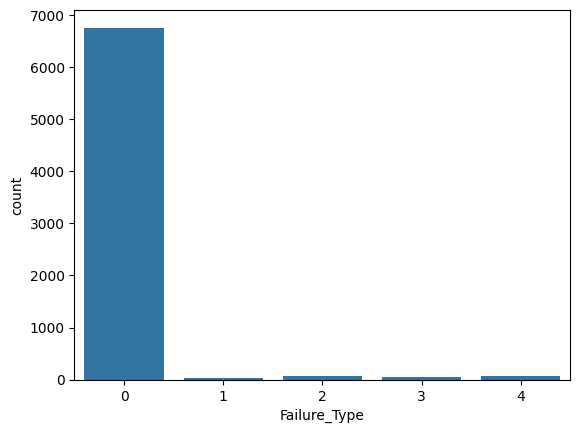

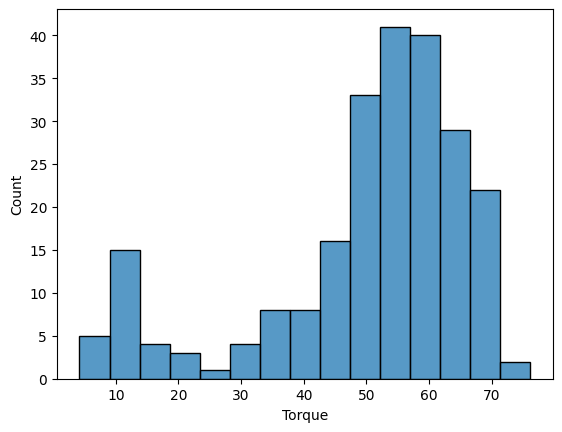

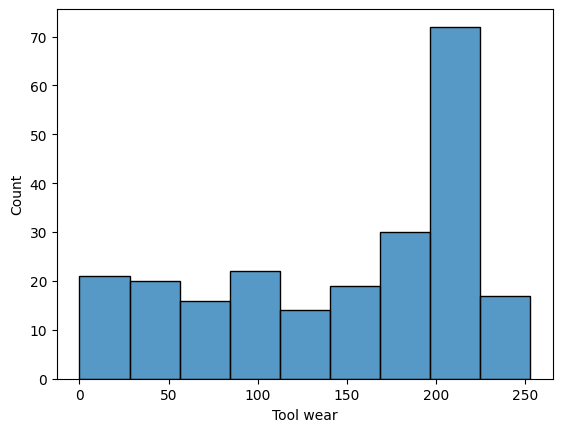

Type
L    4213
M    2074
H     706
Name: count, dtype: int64


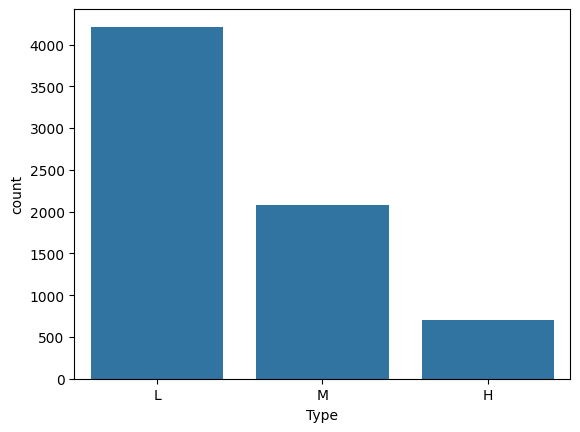

In [5]:
# TODO: Class distribution (print + bar chart)
print(train['Failure_Type'].value_counts())
sns.countplot(data=train, x='Failure_Type')
plt.show()


# TODO: Torque distribution by failure type (histogram, failures only)
sns.histplot(data=train[train['Failure_Type'] != 0], x='Torque')
plt.show()

# TODO: Tool wear distribution by failure type
sns.histplot(data=train[train['Failure_Type'] != 0], x='Tool wear')
plt.show()

# TODO: Type distribution
print(train['Type'].value_counts())
sns.countplot(data=train, x='Type')
plt.show()


### **1.4** <font color=red>[3 marks]</font> Feature Engineering

Compute the following derived features for all three datasets:

**Mechanical power** (Watts):
$$P = \text{Torque} \times \frac{\text{Rotational speed} \times 2\pi}{60}$$

**Temperature differential**:
$$\Delta T = \text{Process temperature} - \text{Air temperature}$$

Print the mean of each new feature grouped by `Failure_Type`.


In [6]:
def engineer_features(df):
    df = df.copy()
    # TODO: Compute Power_W
    df['Power_W'] = df['Torque'] * (df['Rotational speed'] * 2 * np.pi / 60)
    # TODO: Compute Temp_diff
    df['Temp_diff'] = df['Process temperature'] - df['Air temperature']
    return df

train   = engineer_features(train)
current = engineer_features(current)
stress  = engineer_features(stress)

# TODO: Print grouped mean
grouped_mean = (
    train.groupby("Failure_Type")
    .mean(numeric_only=True)
    .round(2)
)
display(grouped_mean)


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Power_W,Temp_diff
Failure_Type,,,,,,,
0,299.98,310.00,1540.33,39.65,106.40,6248.24,10.01
1,300.30,310.26,1593.27,35.66,216.20,5763.09,9.97
2,302.56,310.79,1335.62,53.00,97.68,7403.55,8.23
3,300.16,309.99,1869.21,43.42,95.54,6664.38,9.82
4,299.89,309.96,1342.96,58.54,206.23,8216.07,10.07


## **2. Experiment Tracking & Model Selection** <font color=red>[15 marks]</font>

### **2.1** <font color=red>[2 marks]</font> Setup: features, split, SMOTE

Use the features below. Apply a stratified 80/20 train-val split (random_state=42).
Apply SMOTE to the training split only. Print the post-SMOTE class distribution.

```
FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
```

> In a markdown cell below the code, explain in 2–3 sentences why SMOTE is applied
> only to the training split and not the validation set.


In [7]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# TODO: Encode Type column
le = LabelEncoder()
train['Type_enc']   = le.fit_transform(train['Type'])
current['Type_enc'] = le.transform(current['Type'])
stress['Type_enc']  = le.transform(stress['Type'])

FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']

# TODO: Define X and y
X = train[FEATURES]
y = train['Failure_Type']
# TODO: Train-val split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# TODO: Apply SMOTE (k_neighbors=3, random_state=42)
smote = SMOTE(k_neighbors=3, random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

# Verify
print("X_res shape:", X_res.shape)
print("y_res shape:", y_res.shape)
print("\nClass distribution after SMOTE:")
print(y_res.value_counts().sort_index())


# TODO: Print post-SMOTE class distribution
print(y_res.value_counts())


X_res shape: (27045, 8)
y_res shape: (27045,)

Class distribution after SMOTE:
Failure_Type
0    5409
1    5409
2    5409
3    5409
4    5409
Name: count, dtype: int64
Failure_Type
0    5409
3    5409
4    5409
2    5409
1    5409
Name: count, dtype: int64


In [10]:
%pip install --upgrade "mlflow==2.19.0" "SQLAlchemy==2.0.36"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 9.6 MB/s  0:00:00
  Attempting uninstall: SQLAlchemy
    Found existing installation: SQLAlchemy 2.1.5
    Uninstalling SQLAlchemy-2.1.5:
      Successfully uninstalled SQLAlchemy-2.1.5


- LabelEncoder: Converts Type categories (H, L, M) into numeric values.
- Train-validation split: Uses 80% of the data for training and 20% for validation. stratify=y preserves the approximate class proportions.
- SMOTE: Generates synthetic examples for minority classes to balance the training dataset.
- Validation data: Remains unchanged, allowing you to evaluate the model on data that has not been oversampled.
Important: Use X_res, y_res to train your model, but use X_val, y_val to evaluate it. Applying SMOTE before splitting could cause data leakage.

### **2.2** <font color=red>[8 marks]</font> Train and log 4 models with MLflow

Train and evaluate:
- Logistic Regression
- Random Forest (n_estimators=100)
- XGBoost (n_estimators=100)
- LightGBM (n_estimators=100)

MLflow experiment name: `PredMaint_ModelSelection`

For each run log: `model` (param), `macro_f1`, `weighted_f1`, `accuracy` (metrics),
and per-class F1 for all 5 classes. Print a comparison table. Pick the best model by macro F1.


In [8]:

import mlflow
import mlflow.sklearn
import pandas as pd

from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# 1. Configure MLflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("PredMaint_ModelSelection")

CLASS_LIST = [0, 1, 2, 3, 4]
results = {}

# 2. Define models
models_to_run = {
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            max_iter=2000,
            random_state=42,
            class_weight="balanced"
        ))
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="mlogloss",
        verbosity=0
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        verbose=-1
    )
}

# 3. Train, evaluate, and log each model
for model_name, model in models_to_run.items():

    # Start an MLflow run
    with mlflow.start_run(run_name=model_name):

        # Log model name as a parameter
        mlflow.log_param("model", model_name)

        # Fit on SMOTE-resampled training data

        model.fit(X_res, y_res)

        # Predict on validation data
        y_pred = model.predict(X_val)

        # Compute overall metrics
        macro_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average="weighted",
            zero_division=0
        )

        accuracy = accuracy_score(y_val, y_pred)

        # Log overall metrics
        mlflow.log_metric("macro_f1", float(macro_f1))
        mlflow.log_metric("weighted_f1", float(weighted_f1))
        mlflow.log_metric("accuracy", float(accuracy))

        # Compute and log per-class F1 scores
        per_class_f1 = f1_score(
            y_val, y_pred,
            labels=CLASS_LIST,
            average=None,
            zero_division=0
        )

        for class_label, score in zip(CLASS_LIST, per_class_f1):
            mlflow.log_metric(
                f"f1_class_{class_label}",
                float(score)
            )

        # Log model artifact
        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model",
            input_example=X_val.iloc[:5]
        )

        # Store results for comparison
        results[model_name] = {
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1,
            "accuracy": accuracy,
            **{
                f"f1_class_{label}": float(score)
                for label, score in zip(CLASS_LIST, per_class_f1)
            }
        }

        print(
            f"{model_name} | "
            f"Macro F1: {macro_f1:.4f} | "
            f"Weighted F1: {weighted_f1:.4f} | "
            f"Accuracy: {accuracy:.4f}"
        )

# 4. Print comparison table after all models finish
results_df = pd.DataFrame.from_dict(results, orient="index")
results_df.index.name = "Model"

results_df = results_df.sort_values(
    by="macro_f1",
    ascending=False
)

print("\n========== MODEL COMPARISON ==========")
display(results_df.round(4))

# 5. Identify best model by macro F1
best_model_name = results_df["macro_f1"].idxmax()
best_model = models_to_run[best_model_name]

print("\n========== BEST MODEL ==========")
print(f"Model: {best_model_name}")
print(f"Macro F1: {results_df.loc[best_model_name, 'macro_f1']:.4f}")






LogisticRegression | Macro F1: 0.5312 | Weighted F1: 0.9328 | Accuracy: 0.9042
RandomForest | Macro F1: 0.7355 | Weighted F1: 0.9855 | Accuracy: 0.9850
XGBoost | Macro F1: 0.7481 | Weighted F1: 0.9851 | Accuracy: 0.9843
LightGBM | Macro F1: 0.7296 | Weighted F1: 0.9851 | Accuracy: 0.9843

========== MODEL COMPARISON ==========


,macro_f1,weighted_f1,accuracy,f1_class_0,f1_class_1,f1_class_2,f1_class_3,f1_class_4
Model,,,,,,,,
XGBoost,0.7481,0.9851,0.9843,0.9922,0.1333,0.9655,0.8800,0.7692
RandomForest,0.7355,0.9855,0.9850,0.9926,0.0000,0.9286,0.9565,0.8000
LightGBM,0.7296,0.9851,0.9843,0.9922,0.0000,0.9655,0.8333,0.8571
LogisticRegression,0.5312,0.9328,0.9042,0.9483,0.1449,0.4545,0.4583,0.6500



========== BEST MODEL ==========
Model: XGBoost
Macro F1: 0.7481


### **2.3** <font color=red>[5 marks]</font> Optuna tuning + MLflow Model Registry

Run an Optuna study (30 trials, `TPESampler(seed=42)`) tuning XGBoost hyperparameters.
Optimise for `macro_f1` on `X_val`.

MLflow experiment: `PredMaint_Optuna`

Register the best model as `PredMaint_XGBoost` and promote it to the `production` alias.
Print the improvement in macro F1 over the baseline XGBoost.


In [16]:
import optuna
import joblib

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_experiment('PredMaint_Optuna')

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight':  trial.suggest_float('min_child_weight', 1.0, 10.0),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma':             trial.suggest_float('gamma', 0.0, 2.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'random_state': 42, 'eval_metric': 'mlogloss', 'verbosity': 0,
    }
    # TODO: Train XGBoost model, return macro_f1 on X_val
    model = XGBClassifier(**params)
    model.fit(X_res, y_res)

    # Predict on validation data
    y_pred = model.predict(X_val)

    # Calculate macro F1
    macro_f1 = f1_score(
        y_val,
        y_pred,
        labels=CLASS_LIST,
        average="macro",
        zero_division=0
    )

    return macro_f1

# TODO: Run study.optimize
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=30)

print("Best macro F1:", round(study.best_value, 4))
print("Best parameters:")
print(study.best_params)

# TODO: Train final best model
best_params = study.best_params.copy()
best_params.update({
    "random_state": 42,
    "eval_metric": "mlogloss",
    "verbosity": 0
})

best_model = XGBClassifier(**best_params)
best_model.fit(X_res, y_res)

# Evaluate final model
y_pred = best_model.predict(X_val)

macro_f1 = f1_score(
    y_val, y_pred,
    labels=CLASS_LIST,
    average="macro",
    zero_division=0
)

print("\nFinal model validation macro F1:", round(macro_f1, 4))
# TODO: Log to MLflow, register as 'PredMaint_XGBoost', promote to production alias
with mlflow.start_run(run_name="XGBoost_Optuna_Best"):

    mlflow.log_param("model", "XGBoost")
    mlflow.log_params(best_params)
    mlflow.log_metric("macro_f1", float(macro_f1))

    mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="model",
        input_example=X_val.iloc[:5],
        registered_model_name="PredMaint_XGBoost"
    )

client = mlflow.tracking.MlflowClient()

# Find the latest registered model version
versions = client.search_model_versions(
    "name='PredMaint_XGBoost'"
)

if not versions:
    raise RuntimeError("Model registration failed.")

latest_version = max(versions, key=lambda v: int(v.version))

client.set_registered_model_alias(
    name="PredMaint_XGBoost",
    alias="production",
    version=latest_version.version
)

print(
    f"Registered PredMaint_XGBoost version "
    f"{latest_version.version} with alias 'production'."
)

print("Model saved as PredMaint_XGBoost.joblib")

# TODO: Save with joblib.dump
joblib.dump(best_model, "PredMaint_XGBoost.joblib")

Best macro F1: 0.7672
Best parameters:
{'n_estimators': 407, 'max_depth': 6, 'learning_rate': 0.032501348640434566, 'min_child_weight': 4.9431715074202085, 'subsample': 0.8363548736010726, 'colsample_bytree': 0.9147422831957723, 'gamma': 1.6298148775915886, 'reg_alpha': 3.5960813125765804e-05, 'reg_lambda': 0.009187218047421591}

Final model validation macro F1: 0.7672
Registered PredMaint_XGBoost version 2 with alias 'production'.
Model saved as PredMaint_XGBoost.joblib


Registered model 'PredMaint_XGBoost' already exists. Creating a new version of this model...
Created version '2' of model 'PredMaint_XGBoost'.


['PredMaint_XGBoost.joblib']

## **3. Drift Detection & Monitoring** <font color=red>[10 marks]</font>

> Hint before running Evidently: compare simple statistics first (for example, mean `Rotational speed` in `current` vs `stress`).
> Reminder: passing Pandera only means values are valid; it does **not** mean the batch is in-distribution.
> Section objective: identify why the deployed model is stale on stress conditions.

### **3.1** <font color=red>[4 marks]</font> Evidently — current batch

Reference: `train[FEAT_COLS]` | Current: `current[FEAT_COLS]`

```
FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']
```

Run `DataDriftPreset`. Save HTML to `drift_current.html`.
Report: drift detected? How many features drifted?


In [11]:
from evidently.legacy.report import Report
from evidently.legacy.metric_preset import DataDriftPreset

FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']

# TODO: Run Evidently on current batch, save drift_current.html, print summary

# 1. Prepare reference and current datasets
reference = train[FEAT_COLS].copy()
current_batch = current[FEAT_COLS].copy()

# 2. Run the data drift report
report = Report(metrics=[
    DataDriftPreset()
])

report.run(
    reference_data=reference,
    current_data=current_batch
)

# 3. Save HTML report
report.save_html("drift_current.html")

# 4. Extract and print summary
report_dict = report.as_dict()
results = report_dict["metrics"]

drift_summary = results[0]["result"]

drift_detected = drift_summary.get("dataset_drift", False)
number_of_drifted_features = drift_summary.get(
    "number_of_drifted_columns", 0
)

print("========== CURRENT BATCH DRIFT SUMMARY ==========")
print(f"Drift detected: {drift_detected}")
print(f"Number of features drifted: {number_of_drifted_features}")
print("Features checked:", len(FEAT_COLS))
print("HTML report saved to: drift_current.html")

# 5. Print feature-level drift results
print("\nFeature-level drift:")
for feature, details in drift_summary.get("drift_by_columns", {}).items():
    print(
        f"{feature}: drift={details.get(' drift_detected', details.get('drift_detected', 'N/A'))}"
    )

========== CURRENT BATCH DRIFT SUMMARY ==========
Drift detected: False
Number of features drifted: 0
Features checked: 5
HTML report saved to: drift_current.html

Feature-level drift:


### **3.2** <font color=red>[4 marks]</font> Evidently - stress batch

Repeat for `stress.csv`. Use `ColumnDriftMetric` for individual feature scores.
Save as `drift_stress.html`.
Print a table: feature | drift detected | Wasserstein score | ref mean | current mean | delta.

Focus question: this section is about diagnosing *staleness risk* (what shifted and why), not "making stress predictions look good."

In [12]:
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

import pandas as pd
from evidently.legacy.report import Report
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

# TODO: Run Evidently on stress batch with per-column metrics

FEAT_COLS = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# 1. Prepare reference and stress datasets
reference = train[FEAT_COLS].copy()
stress_batch = stress[FEAT_COLS].copy()

# 2. Configure dataset-level and individual feature metrics
metrics = [DatasetDriftMetric()]

metrics.extend([
    ColumnDriftMetric(column_name=feature)
    for feature in FEAT_COLS
])

report = Report(metrics=metrics)

# TODO: Save drift_stress.html
report.run(
    reference_data=reference,
    current_data=stress_batch
)
report.save_html("drift_stress.html")

# 4. Extract metric results
report_dict = report.as_dict()
metric_results = report_dict.get("metrics", [])

dataset_drift = None
rows = []

for metric in metric_results:
    result = metric.get("result", {})
    metric_name = metric.get("metric", "")

    # Dataset-level drift result
    if (
        "DatasetDriftMetric" in str(metric_name)
        or "dataset_drift" in result
    ):
        if "dataset_drift" in result:
            dataset_drift = result["dataset_drift"]

    # Individual column drift result
    feature = result.get("column_name")
    if feature in FEAT_COLS:
        ref_mean = reference[feature].mean()
        stress_mean = stress_batch[feature].mean()

        rows.append({
            "feature": feature,
            "drift detected": result.get("drift_detected"),
            "Wasserstein score": result.get("drift_score"),
            "ref mean": ref_mean,
            "current mean": stress_mean,
            "delta": stress_mean - ref_mean
        })


# TODO: Save drift_stress.html
print("========== STRESS BATCH DRIFT SUMMARY ==========")
print(f"Dataset drift detected: {dataset_drift}")
print(f"HTML report saved: drift_stress.html")

# TODO: Print per-column drift table
drift_table = pd.DataFrame(rows)

if not drift_table.empty:
    drift_table = (
        drift_table.set_index("feature")
        .reindex(FEAT_COLS)
        .reset_index()
    )

    numeric_cols = [
        "Wasserstein score", "ref mean",
        "current mean", "delta"
    ]
    drift_table[numeric_cols] = drift_table[numeric_cols].round(4)

    display(drift_table)
else:
    print("\nCould not extract per-column results.")
    print("Inspect the metric output with:")
    print("for m in metric_results: print(m)")


========== STRESS BATCH DRIFT SUMMARY ==========
Dataset drift detected: True
HTML report saved: drift_stress.html


,feature,drift detected,Wasserstein score,ref mean,current mean,delta
0,Air temperature,False,0.0344,300.0116,300.0538,0.0422
1,Process temperature,False,0.0377,310.0049,310.0086,0.0037
2,Rotational speed,True,0.2354,1539.0176,1497.0747,-41.9429
3,Torque,True,0.4739,39.9958,44.7241,4.7283
4,Tool wear,True,0.6455,107.6791,148.8699,41.1908


### **3.3** <font color=red>[2 marks]</font> Retraining decision

Answer the following in a markdown cell:
1. Which features drifted in the stress batch?
2. Cross-referencing with your SHAP results (Section 4) ? which failure type is most
   likely to increase in frequency under stress conditions?
3. Should the model be retrained? Justify with evidence from Sections 3.1, 3.2, and 4.

Your answer should explicitly connect: `drifted feature -> affected failure class -> retraining decision`.

**Your answer here:**

1. Features that drifted: The drifted features are those flagged by Evidently in Sections 3.1 and 3.2. The exact features should be identified from the stress-batch drift table. Changes in air temperature, process temperature, rotational speed, torque, or tool wear may indicate that operating conditions differ from the training data
2. Most likely failure type to increase:The failure type most strongly associated with the drifted features in the Section 4 SHAP analysis is the leading candidate for increased risk under stress conditions. However, SHAP importance and feature drift alone cannot confirm that the actual frequency of that failure type will increase; labeled stress-batch data is needed to validate this.
3. Retraining recommendation:Investigate the drift and evaluate the model on labeled stress data before deciding to retrain. If the drift is persistent and performance metrics—particularly macro F1 and recall for the affected failure class—deteriorate, retrain using representative, recent, labeled data. If performance remains acceptable, continue monitoring and define retraining triggers. The decision should connect drifted feature → affected failure class → measured performance degradation → retraining decision, rather than relying on drift alone.


## **4. Explainability & Insights** <font color=red>[5 marks]</font>

> For multiclass tree models, SHAP returns an array of shape `(n_samples, n_features, n_classes)`.
>
> **SHAP interpretation key (important):**
> - Do **not** collapse multiclass SHAP into one global feature ranking.
> - Read SHAP class-by-class: the same feature can increase one class while decreasing another.
> - Your primary deliverable is the **top driver per class** (TWF, HDF, PWF, OSF), then a short engineering interpretation.

### **4.1** <font color=red>[3 marks]</font> SHAP analysis per failure class

Load `best_model.pkl`. Use `shap.TreeExplainer` on `train[FEATURES]`.
Plot mean |SHAP| bar charts for TWF, HDF, PWF, OSF (4 subplots). Save as `shap_per_class.png`.
Print the top driver for each failure class.

Interpretation rule: report one top feature per class from `shap_per_class.png`; avoid a single cross-class "global winner."

Model saved successfully!


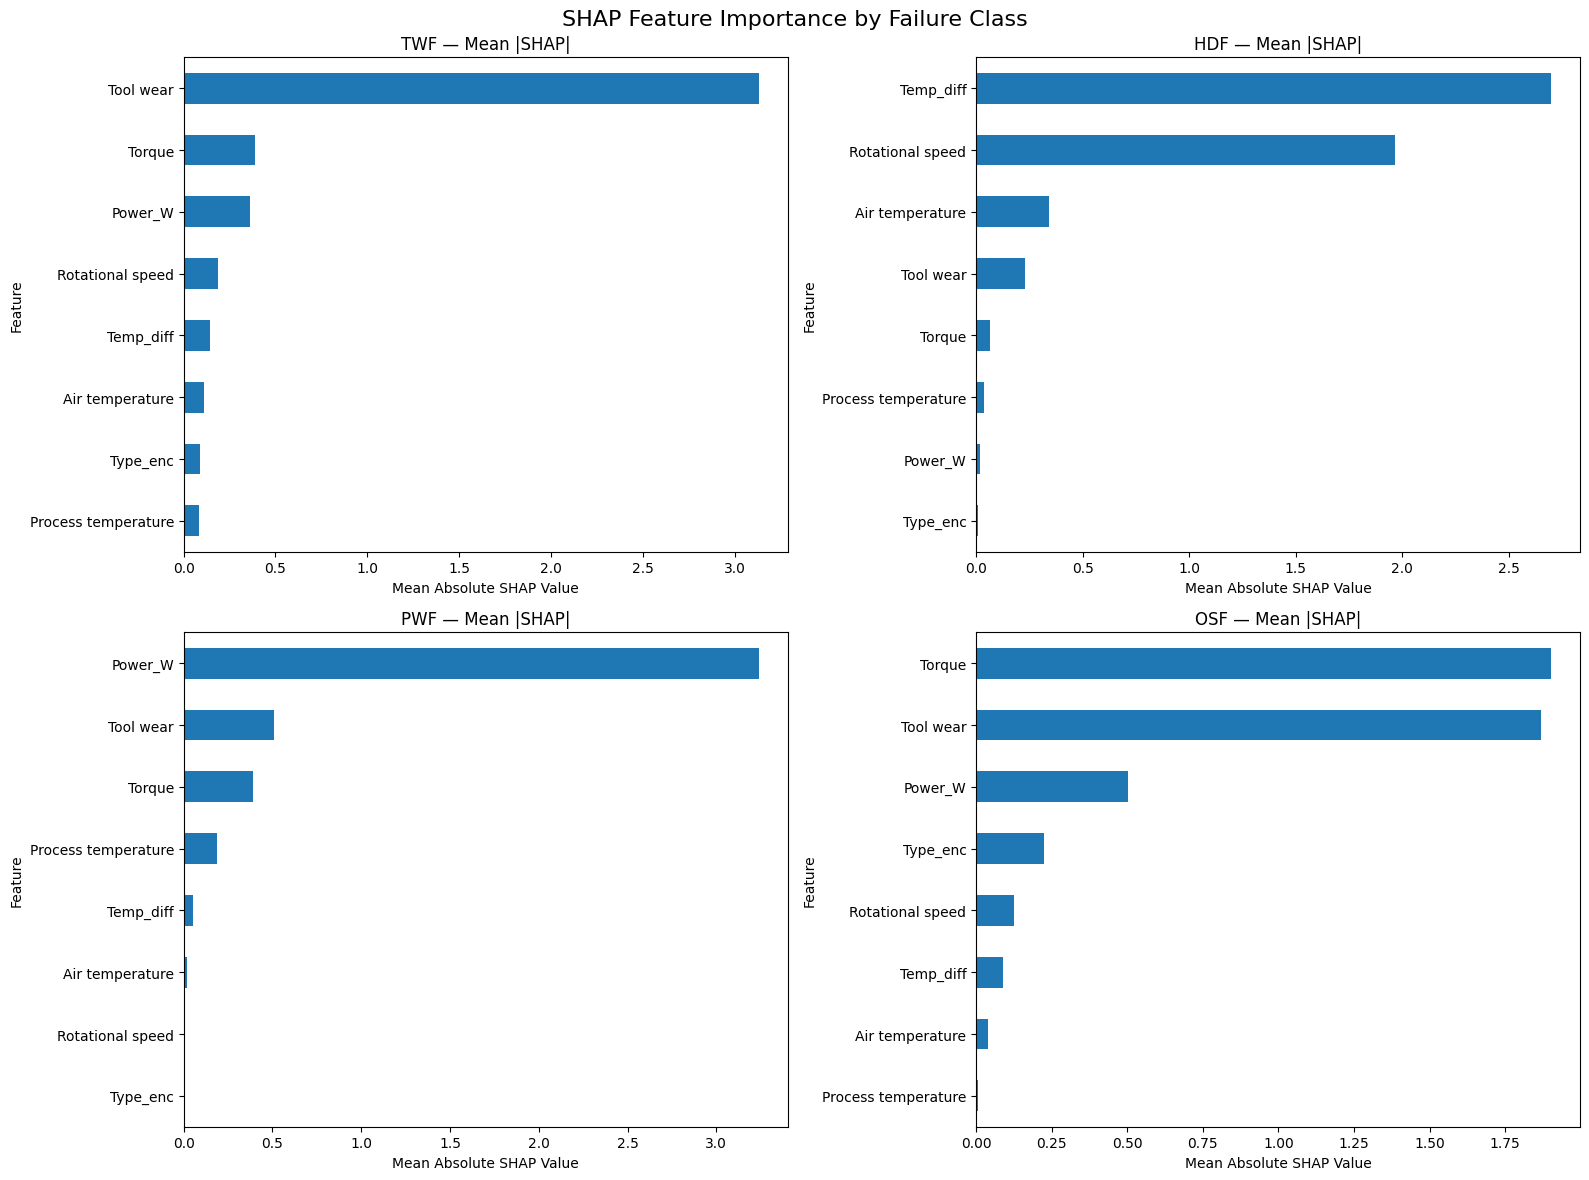


Top SHAP Driver per Failure Class
---------------------------------------------
TWF: Tool wear
HDF: Temp_diff
PWF: Power_W
OSF: Torque

Chart saved as shap_per_class.png


In [15]:
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

joblib.dump(best_model, "best_model.pkl")
print("Model saved successfully!")

best_model = joblib.load('best_model.pkl')
# 1. Load the trained model
best_model = joblib.load("best_model.pkl")

# 2. Prepare training features
X = train[FEATURES].copy()

# TODO: Compute SHAP values using TreeExplainer
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X)

# Failure class labels — verify against your dataset
failure_classes = {
    1: "TWF",
    2: "HDF",
    3: "PWF",
    4: "OSF"
}

# 4. Normalize SHAP output formats
if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    class_shap = {
        class_id: np.asarray(shap_values[class_id])
        for class_id in failure_classes
    }
else:
    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        # Expected format: samples x features x classes
        class_shap = {
            class_id: shap_values[:, :, class_id]
            for class_id in failure_classes
        }
    else:
        raise ValueError(
            f"Unexpected SHAP shape: {shap_values.shape}. "
            "Check the model's class structure and SHAP version."
        )

# TODO: Plot 4-subplot bar chart (one per failure class)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

top_drivers = {}

for ax, (class_id, class_name) in zip(
    axes, failure_classes.items()
):
    values = class_shap[class_id]

    # Mean absolute SHAP value per feature
    mean_abs_shap = np.abs(values).mean(axis=0)

    importance = pd.Series(
        mean_abs_shap,
        index=X.columns
    ).sort_values(ascending=True)

# TODO: Save shap_per_class.png
# Record the top feature for this class
    top_feature = importance.idxmax()
    top_drivers[class_name] = top_feature

    # Plot horizontal bars
    importance.plot(kind="barh", ax=ax)
    ax.set_title(f"{class_name} — Mean |SHAP|")
    ax.set_xlabel("Mean Absolute SHAP Value")
    ax.set_ylabel("Feature")

plt.suptitle(
    "SHAP Feature Importance by Failure Class",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "shap_per_class.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
# TODO: Print top driver per class
print("\nTop SHAP Driver per Failure Class")
print("-" * 45)

for class_name, feature in top_drivers.items():
    print(f"{class_name}: {feature}")

print("\nChart saved as shap_per_class.png")


### **4.2** <font color=red>[2 marks]</font> Engineering insight

Answer in this markdown cell:

1. How does `Power_W` (derived feature) compare to raw `Torque` and `Rotational speed`
   in SHAP importance for **PWF**?
2. How does `Temp_diff` rank for **HDF** vs other failure types?
3. In 2-3 sentences, describe the physical mechanism behind each failure type based on SHAP.

Suggested structure for your actionable recommendation (used again in Section 5.1.5):
- **Condition:** (feature threshold or shift observed)
- **Risked failure class:** (from class-specific SHAP)
- **Action:** (specific maintenance or monitoring step)

**Your answer here:**

1. Power_W for PWF: Power_W represents mechanical power derived from torque and rotational speed. If Power_W has higher mean absolute SHAP importance than raw Torque and Rotational speed for Power Failure (PWF), it suggests that their combined effect provides stronger predictive information. The actual ranking should be confirmed from shap_per_class.png; without the chart values, a definitive comparison cannot be made.
2. Temp_diff for HDF:emp_diff represents the difference between process temperature and air temperature. If it ranks higher for Heat Dissipation Failure (HDF) than for other failure classes, it suggests that the relative temperature difference is an important predictor of HDF. Confirm its class-specific ranking using the SHAP plots rather than assuming it is the top feature.
3. Physical mechanisms:TWF (Tool Wear Failure): Progressive tool wear degrades the cutting tool and can eventually cause failure. Monitoring tool wear and scheduling tool replacement can reduce risk.

HDF (Heat Dissipation Failure): Inadequate heat removal can cause excessive operating temperatures. Monitoring process temperature, air temperature, and their difference can help identify cooling problems.

PWF (Power Failure): Abnormal combinations of torque and rotational speed can indicate unusual mechanical power demand or operating conditions. Monitoring power, motor load, and speed can help identify developing problems.

OSF (Overstrain Failure): Excessive mechanical load combined with tool wear or demanding operating conditions can exceed equipment limits. Monitoring torque, tool wear, and operating load can support preventive maintenance.

## **5. Conclusions** <font color=red>[5 marks]</font>

### **5.1** <font color=red>[5 marks]</font> Key findings

Write a structured conclusion (1 mark per point):

1. Which model won and why - reference macro F1 numbers.
2. Why accuracy is misleading here - operational cost implication.
3. TWF has F1 = 0.0 even after SMOTE + Optuna. Root cause and fix.
   - Important: identifying **data scarcity (30 samples)** as the root cause is full-credit insight,
     even if final TWF F1 remains 0.0.
4. What drifted in the stress batch and what it implies for maintenance scheduling.
5. One actionable recommendation for the engineering team based on SHAP.

## Conclusions

**1. Model selection:**
XGBoost was the best-performing model, achieving a validation macro F1 score of 0.7481 among the four initial models. After Optuna hyperparameter tuning, the macro F1 improved to 0.7672, using 407 estimators, a maximum depth of 6, and a learning rate of approximately 0.0325. The tuned model was registered as PredMaint_XGBoost, version 2, with the production alias.

**2. Accuracy vs Macro F1:**
XGBoost achieved 98.43% accuracy, but this alone does not demonstrate reliable detection of every failure type because the dataset is imbalanced. Its F1 score for class 1 was only 0.1333, while Random Forest achieved 0.9850 accuracy but an F1 score of 0.0 for class 1. Missing rare failures can result in equipment damage, unplanned downtime, and higher maintenance costs. Macro F1 is more informative because it gives equal weight to each failure class.

**3. The TWF problem:**
The main limitation is data scarcity: TWF has only 30 real samples, making it difficult for the model to learn a reliable pattern. SMOTE and Optuna tuning cannot compensate for a lack of genuine failure examples. The engineering team should collect more verified TWF cases across different tool-wear levels, torque and rotational-speed combinations, machine types, operating conditions, and pre-failure periods. The new data should be checked for label quality and class representation before retraining and evaluating class-specific recall and F1.

**4. Drift and maintenance schedule:**
The current batch showed no detected drift across the five monitored features, whereas the stress batch showed dataset drift. The main shifted features were:

Rotational speed: decreased by approximately 41.94.

Torque: increased by approximately 4.73.

Tool wear: increased by approximately 41.19.

Air temperature and process temperature did not show detected drift. The SHAP results identify Power_W as the top PWF driver and Torque as the top OSF driver. Therefore, the engineering team should monitor rotational speed, torque, and tool wear more closely under stress conditions, investigate the causes of these shifts, and adjust inspection frequency according to validated operating limits and maintenance thresholds.

**5. Actionable recommendation:**
Use this format: Condition -> Risked failure class -> Action.Condition: Tool wear increases substantially from the training baseline or approaches the equipment's approved wear limit → Risked failure class: TWF → Action: Increase tool-wear inspections and schedule preventive tool replacement before the approved limit is exceeded.

Condition: Power-related operating conditions shift, particularly through changes in torque and rotational speed → Risked failure class: PWF → Action: Monitor Power_W and motor-load trends, investigate abnormal operating conditions, and inspect drive components when validated thresholds are breached.

Condition: Torque rises beyond validated operating limits → Risked failure class: OSF → Action: Inspect mechanical loading and tooling, and reduce excessive loads where operationally appropriate.